# Efficient Stellar Classification Through Feature Reduction

**Dataset:** Stellar Classification Dataset (SDSS)

**Problem Statement:**
How much can the number of astronomical observations be reduced while maintaining accurate classification of stars, galaxies, and quasars using machine learning?

**Author:** Abdullah Irshad CT-24271

## 1. Import libraries and load the dataset

The original dataset is kept unchanged.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

plt.rcParams["figure.figsize"] = (9, 5) # Default plots to 9,5 inches

In [2]:
# Load the data set

df = pd.read_csv("Data/star_classification.csv")
df.head()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


### 1.1 Separate the input features and target

`u`, `g`, `r`, `i`, and `z` are five separate photometric bands. The `z` magnitude is **not** the same thing as `redshift`.

The coordinates are retained in the cleaned dataset for inspection, but excluded from the primary inputs because sky location can encode survey footprint or selection effects. They can be tested as a separate experiment later.

In [3]:
TARGET = "class"
PRIMARY_FEATURES = ["u", "g", "r", "i", "z", "redshift"]

print("Target:", TARGET)
print("Primary input features:", PRIMARY_FEATURES)
print("Number of primary input features:", len(PRIMARY_FEATURES))

df_eda = df.copy()
df_eda.replace(-9999, np.nan, inplace=True) # Replace -9999 with NaN for easier handling of missing values

X_initial = df_eda[PRIMARY_FEATURES]
y_initial = df_eda[TARGET]
print("X shape:", X_initial.shape)
print("y shape:", y_initial.shape)

Target: class
Primary input features: ['u', 'g', 'r', 'i', 'z', 'redshift']
Number of primary input features: 6
X shape: (100000, 6)
y shape: (100000,)


In [4]:
print("Dataset information:")
df.info()

print("\nNumerical summary:")
display(df.describe().T)

print("\nTarget values:")
display(df[TARGET].value_counts().to_frame("Count"))

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  str    
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-null  int64  
dtypes: float64(10),

,count,mean,std,min,25%,50%,75%,max
obj_ID,100000.0,1.237665e+18,8.438560e+12,1.237646e+18,1.237659e+18,1.237663e+18,1.237668e+18,1.237681e+18
alpha,100000.0,1.776291e+02,9.650224e+01,5.527828e-03,1.275182e+02,1.809007e+02,2.338950e+02,3.599998e+02
delta,100000.0,2.413530e+01,1.964467e+01,-1.878533e+01,5.146771e+00,2.364592e+01,3.990155e+01,8.300052e+01
u,100000.0,2.198047e+01,3.176929e+01,-9.999000e+03,2.035235e+01,2.217914e+01,2.368744e+01,3.278139e+01
g,100000.0,2.053139e+01,3.175029e+01,-9.999000e+03,1.896523e+01,2.109983e+01,2.212377e+01,3.160224e+01
r,100000.0,1.964576e+01,1.854760e+00,9.822070e+00,1.813583e+01,2.012529e+01,2.104478e+01,2.957186e+01
i,100000.0,1.908485e+01,1.757895e+00,9.469903e+00,1.773228e+01,1.940514e+01,2.039650e+01,3.214147e+01
z,100000.0,1.866881e+01,3.172815e+01,-9.999000e+03,1.746068e+01,1.900460e+01,1.992112e+01,2.938374e+01
run_ID,100000.0,4.481366e+03,1.964765e+03,1.090000e+02,3.187000e+03,4.188000e+03,5.326000e+03,8.162000e+03
rerun_ID,100000.0,3.010000e+02,0.000000e+00,3.010000e+02,3.010000e+02,3.010000e+02,3.010000e+02,3.010000e+02



Target values:


,Count
class,
GALAXY,59445
STAR,21594
QSO,18961


# 2. Exploratory Data Analysis
## 2.1 Target Distribution

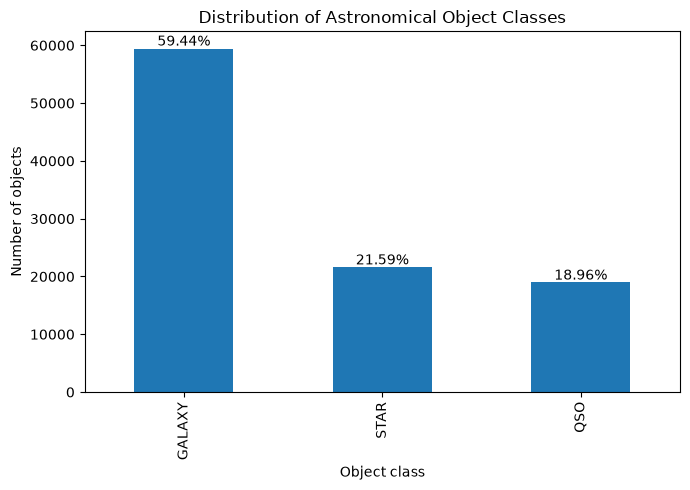

In [5]:
# Count the number of instances in each class and calculate percentages.
class_counts = df[TARGET].value_counts()
class_percentages = (df[TARGET].value_counts(normalize=True) * 100).round(2)

fig, ax = plt.subplots(figsize=(7, 5))
class_counts.plot(kind="bar", ax=ax)
ax.set_title("Distribution of Astronomical Object Classes")
ax.set_xlabel("Object class")
ax.set_ylabel("Number of objects")
for i, label in enumerate(class_counts.index):
    ax.text(i, class_counts[label] + 500, f"{class_percentages[label]}%", ha="center")
plt.tight_layout()
plt.show()

## 2.2 Distributions of the Main Features
The `-9999` values were represented as missing so as to not distort the measurement scales.

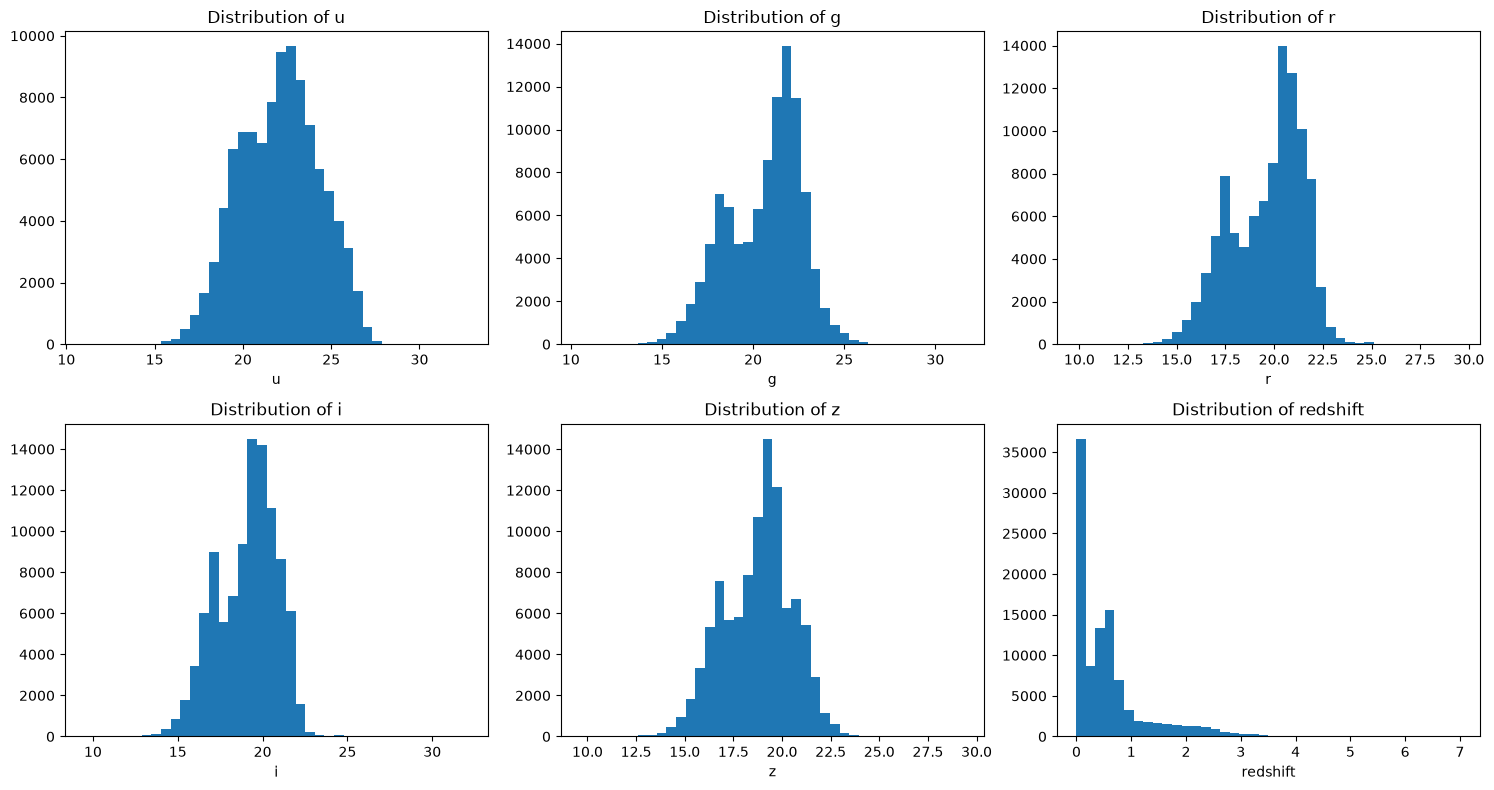

In [6]:
plot_features = ["u", "g", "r", "i", "z", "redshift"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for feature, ax in zip(plot_features, axes.flatten()):
    ax.hist(df_eda[feature].dropna(), bins=40)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
plt.tight_layout()
plt.show()

## 2.3 Relevance of Redshift
The following plot helps us understand whether the spectroscopic redshift distribution differs across the target classes.

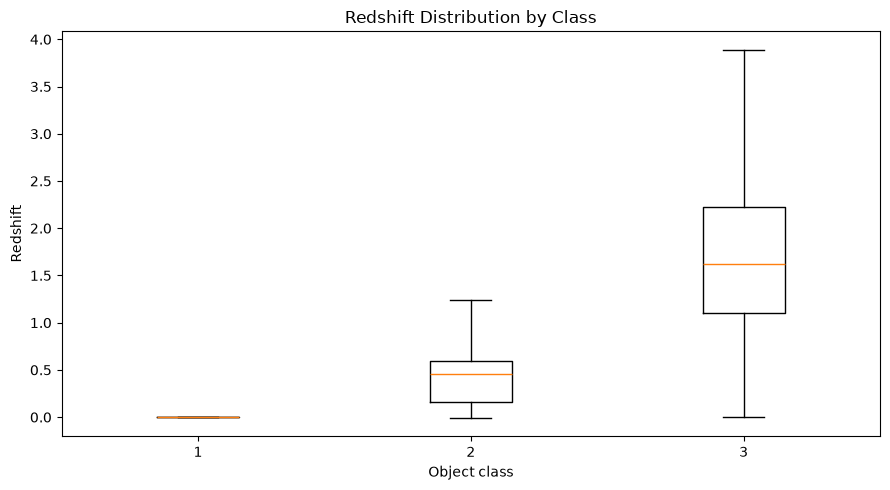

,count,median,mean,std
class,,,,
GALAXY,59445,0.4563,0.4216,0.2649
QSO,18961,1.6172,1.7197,0.9140
STAR,21594,-0.0001,-0.0001,0.0005


In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
redshift_by_class = [df_eda.loc[df_eda["class"] == label, "redshift"].dropna() for label in ["STAR", "GALAXY", "QSO"]]
ax.boxplot(redshift_by_class, label=["STAR", "GALAXY", "QSO"], showfliers=False)
ax.set_title("Redshift Distribution by Class")
ax.set_xlabel("Object class")
ax.set_ylabel("Redshift")
plt.tight_layout()
plt.show()

display(df_eda.groupby("class")["redshift"].agg(["count", "median", "mean", "std"]).round(4))

## 2.4 Correlation between Main Features
<p>The following are the main features:

> `u`,`g`,`r`,`i`,`z` and `redshift` 
</p>

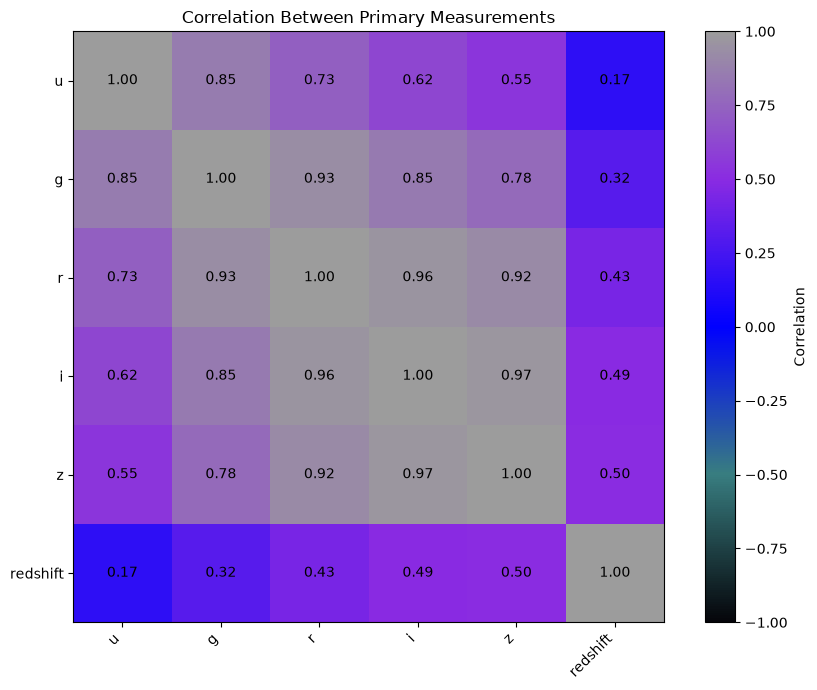

,u,g,r,i,z,redshift
u,1.000,0.853,0.729,0.618,0.546,0.167
g,0.853,1.000,0.933,0.847,0.775,0.319
r,0.729,0.933,1.000,0.963,0.919,0.433
i,0.618,0.847,0.963,1.000,0.972,0.492
z,0.546,0.775,0.919,0.972,1.000,0.501
redshift,0.167,0.319,0.433,0.492,0.501,1.000


In [8]:
correlation_features = ["u", "g", "r", "i", "z", "redshift"]
correlation_matrix = df_eda[correlation_features].corr()

fig, ax = plt.subplots(figsize=(9, 7))

cmap_supernova = LinearSegmentedColormap.from_list("supernova_blast", ["#9C9C9C", "#8A2BE2", "#0000FF", "#387D80", "#05050A"])

supernova = cmap_supernova.reversed()

image = ax.imshow(correlation_matrix, vmin=-1, vmax=1, cmap=supernova)
ax.set_xticks(range(len(correlation_features)), labels=correlation_features, rotation=45, ha="right")
ax.set_yticks(range(len(correlation_features)), labels=correlation_features)
for row in range(len(correlation_features)):
    for col in range(len(correlation_features)):
        ax.text(col, row, f"{correlation_matrix.iloc[row, col]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="Correlation")
ax.set_title("Correlation Between Primary Measurements")
plt.tight_layout()
plt.show()

display(correlation_matrix.round(3))

## 2.5 Alpha and Delta Plots
The right ascension and declination coordinates are plotted to observe which class appears more frequenlty in the sky. Ofcourse due to imbalance one class will be easily viewed accross the plot. `random_state=42` is used to give reproducible plot.

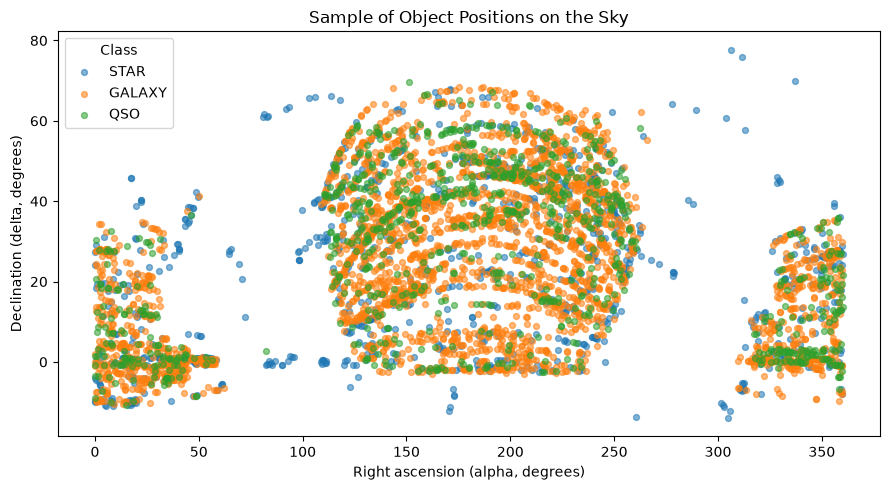

In [9]:
# Due to device bottleneck we'll be selecting a sample of points to be displayed.

coordinate_sample = df_eda.sample(n=min(5000, len(df_eda)), random_state=42)
fig, ax = plt.subplots(figsize=(9, 5))
for label in ["STAR", "GALAXY", "QSO"]:
    subset = coordinate_sample[coordinate_sample["class"] == label]
    ax.scatter(subset["alpha"], subset["delta"], label=label, alpha=0.55, s=18)
ax.set_title("Sample of Object Positions on the Sky")
ax.set_xlabel("Right ascension (alpha, degrees)")
ax.set_ylabel("Declination (delta, degrees)")
ax.legend(title="Class")
plt.tight_layout()
plt.show()

### 2.6 Initial insights from the EDA
1. **Class Distribution:** GALAXY is the largest followed by STAR and then QSO. We'll use stratify in train_test_split.
2. **Missing Values:** There were no missing values besides the `-9999` in `u`,`g`, and `z` columns in one single row which were replaced by NaN and should be treated as missing values as of now.
3. **Redshift:** The class-wise redshift summaries and boxplot show very different distributions, especially for stars compared with galaxies and quasars.
4. **Correlation b/w Main Features:** Several photometric bands are strongly correlated (for example, `r` with `i`, and `i` with `z`). This suggests possible redundancy, but the effect of removing bands must be evaluated rather than assumed.
5. **Metadata and identifiers:** Several columns identify catalogue records, survey runs, camera fields, plates, or fibers. These columns do not directly describe the physical brightness or spectrum of an object and are excluded from the primary predictors.

# 3. Identify data quality issues

The issue is shown before it is fixed. In particular, `-9999` is not a normal missing value (`NaN`), so a standard `isnull()` check alone does not detect it.

### 3.1 Standard missing values and SDSS sentinel values

SDSS documentation explains that a quantity that was not calculated can be stored as `-9999`. Therefore, the values in the affected magnitude fields should be treated as missing, not as real magnitudes.

Reference: [SDSS SkyServer — Excluding Invalid Data Values](https://skyserver.sdss.org/dr16/en/help/docs/sql_help.aspx)

In [10]:
print("Standard missing values in the original file:")
display(df.isna().sum().to_frame("Missing count"))

sentinel_counts = (df.select_dtypes(include=np.number) == -9999).sum()
print("\nOccurrences of -9999 by column:")
display(sentinel_counts[sentinel_counts > 0].to_frame("-9999 count"))

sentinel_rows = df[(df.select_dtypes(include=np.number) == -9999).any(axis=1)]
print("Rows containing at least one -9999:", len(sentinel_rows))
display(sentinel_rows)

Standard missing values in the original file:


,Missing count
obj_ID,0
alpha,0
delta,0
u,0
g,0
r,0
i,0
z,0
run_ID,0
rerun_ID,0



Occurrences of -9999 by column:


,-9999 count
u,1
g,1
z,1


Rows containing at least one -9999: 1


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
79543,1.237649e+18,224.006526,-0.624304,-9999.0,-9999.0,18.1656,18.01675,-9999.0,752,301,2,537,3.731277e+18,STAR,0.000089,3314,54970,162


### 3.2 Duplicate records

In [11]:
duplicate_count = df.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)

Exact duplicate rows: 0


### 3.3 Data types and constant columns

In [12]:
dtype_report = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Unique values": df.nunique(dropna=False)
})
display(dtype_report)

constant_columns = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print("Constant columns:", constant_columns)

# Check class labels for extra spaces, inconsistent capitalization, or unexpected values.
original_labels = df["class"].astype(str)
normalized_labels = original_labels.str.strip().str.upper()
valid_labels = {"STAR", "GALAXY", "QSO"}
print("Class labels in file:", sorted(original_labels.unique()))
print("Labels needing standardization:", int((original_labels != normalized_labels).sum()))
print("Unexpected class labels:", sorted(set(normalized_labels.unique()) - valid_labels))

,Data type,Unique values
obj_ID,float64,78053
alpha,float64,99999
delta,float64,99999
u,float64,93748
g,float64,92651
r,float64,91901
i,float64,92019
z,float64,92007
run_ID,int64,430
rerun_ID,int64,1


Constant columns: ['rerun_ID']
Class labels in file: ['GALAXY', 'QSO', 'STAR']
Labels needing standardization: 0
Unexpected class labels: []


### 3.4 Outlier inspection

The 1.5 × IQR rule is used only to flag unusual values for investigation. Astronomical measurements can have legitimate extreme values, and redshift distributions naturally differ between stars, galaxies, and quasars. Therefore, flagged observations are **not automatically deleted**.

,IQR lower bound,IQR upper bound,Potential outlier count
alpha,-32.047,393.460,0
delta,-46.985,92.034,0
u,15.350,28.690,55
g,14.227,26.862,98
r,13.772,25.408,132
i,13.736,24.393,198
z,13.770,23.612,319
redshift,-0.920,1.679,8990


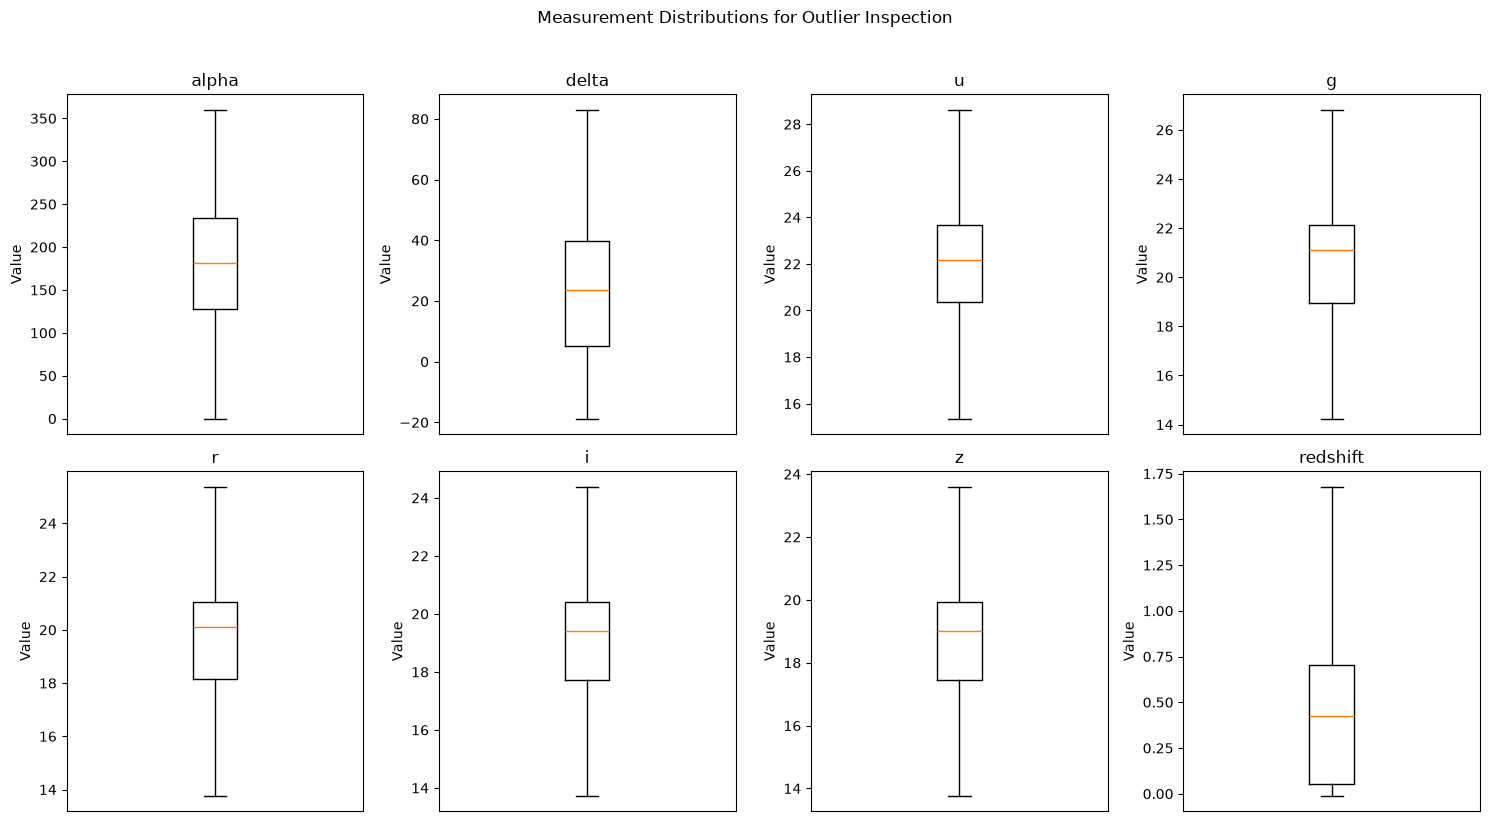

In [13]:
measurement_columns = ["alpha", "delta", "u", "g", "r", "i", "z", "redshift"]
measurement_data = df_eda[measurement_columns]
q1 = measurement_data.quantile(0.25)
q3 = measurement_data.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier_mask = (measurement_data.lt(lower_bound) | measurement_data.gt(upper_bound))
outlier_counts = outlier_mask.sum().sort_values(ascending=False)

display(pd.DataFrame({
    "IQR lower bound": lower_bound,
    "IQR upper bound": upper_bound,
    "Potential outlier count": outlier_mask.sum()
}).round(3))

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for column, ax in zip(measurement_columns, axes.flatten()):
    ax.boxplot(measurement_data[column].dropna(), showfliers=False)
    ax.set_title(column)
    ax.set_xticks([])
    ax.set_ylabel("Value")
fig.suptitle("Measurement Distributions for Outlier Inspection", y=1.02)
plt.tight_layout()
plt.show()

### 3.5 Range checks

Right ascension is expected to be between 0 and 360 degrees, and declination between -90 and +90 degrees. These checks help identify impossible coordinate values. Negative redshift measurements can occur in observed catalogues because of measurement uncertainty and local motion; they should not be removed only because they are negative.

In [14]:
range_checks = pd.DataFrame({
    "Check": ["alpha between 0 and 360", "delta between -90 and 90", "redshift below 0"],
    "Count": [
        ((df_eda["alpha"] < 0) | (df_eda["alpha"] > 360)).sum(),
        ((df_eda["delta"] < -90) | (df_eda["delta"] > 90)).sum(),
        (df_eda["redshift"] < 0).sum()
    ]
})
display(range_checks)

,Check,Count
0,alpha between 0 and 360,0
1,delta between -90 and 90,0
2,redshift below 0,13724


## 4. Basic data cleaning

### Decisions

1. Replace the SDSS sentinel `-9999` with `NaN` so that missing measurements are handled correctly.
2. Keep the one row with missing magnitudes because its class and other measurements are available. Imputation will be learned from the training split later.
3. Remove the following as they are only metadata from the cleaned modelling dataset: `obj_ID`, `run_ID`, `rerun_ID`, `cam_col`, `field_ID`, `spec_obj_ID`, `plate`, `MJD`, and `fiber_ID`.
4. Keep `alpha` and `delta` in the cleaned file for inspection, but leave them out of the primary model inputs to reduce the risk of learning sky-position or survey-footprint patterns.
5. Convert measurement columns to numeric and keep `class` as a label.

> **Note to Self:** Do not delete IQR-flagged values automatically because they may be real astronomical measurements.

In [15]:
df_cleaned = df.copy()

# Convert the invalid sentinel to a true missing value.
numeric_columns = df_cleaned.select_dtypes(include=np.number).columns
sentinel_total_before = int((df_cleaned[numeric_columns] == -9999).sum().sum())
df_cleaned.replace(-9999, np.nan, inplace=True)

# Remove IDs and survey/instrument metadata from this cleaned modelling dataset.
columns_to_remove = [
    "obj_ID", "run_ID", "rerun_ID", "cam_col", "field_ID",
    "spec_obj_ID", "plate", "MJD", "fiber_ID"
]
columns_removed = [c for c in columns_to_remove if c in df_cleaned.columns]
df_cleaned.drop(columns=columns_removed, inplace=True)

# Ensure scientific measurement columns are numeric.
for col in ["alpha", "delta", "u", "g", "r", "i", "z", "redshift"]:
    df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors="coerce")

# Standardize class labels by trimming spaces and using uppercase.
df_cleaned["class"] = df_cleaned["class"].astype(str).str.strip().str.upper()

print("Sentinel values converted:", sentinel_total_before)
print("Columns removed:", columns_removed)
print("Cleaned dataset shape:", df_cleaned.shape)
print("\nMissing values after cleaning:")
display(df_cleaned.isna().sum().to_frame("Missing count"))

Sentinel values converted: 3
Columns removed: ['obj_ID', 'run_ID', 'rerun_ID', 'cam_col', 'field_ID', 'spec_obj_ID', 'plate', 'MJD', 'fiber_ID']
Cleaned dataset shape: (100000, 9)

Missing values after cleaning:


,Missing count
alpha,0
delta,0
u,1
g,1
r,0
i,0
z,1
class,0
redshift,0


### Save the cleaned dataset separately
The cleaned dataset contains the basic cleaning and also retains the missing valeus as NaN. Imputation is not written in the cleaned csv as it must be fitted on training data only.

In [16]:
PATH = "Data/star_classification_cleaned.csv"
df_cleaned.to_csv(PATH, index=False)
print("Cleaned dataset saved to 'Data/star_classification_cleaned.csv'")
print("Cleaned CSV shape:", pd.read_csv(PATH).shape)

Cleaned dataset saved to 'Data/star_classification_cleaned.csv'
Cleaned CSV shape: (100000, 9)


## 5. Feature engineering: colour indices

Colour indices are differences between photometric magnitudes. They describe colour information using the existing measurements:

- `u_g = u - g`
- `g_r = g - r`
- `r_i = r - i`
- `i_z = i - z`

These are derived features, not independent observations. They are created after basic cleaning and before the train-test split. Missing values in the original magnitudes remain missing in the derived features and are imputed later using training data only.

The cleaned CSV saved above remains the basic-cleaned dataset. Feature engineering is applied to a separate copy for modelling.

Derived feature summary:


,count,mean,std,min,25%,50%,75%,max
u_g,99999.0,1.449,1.179,-12.748,0.631,1.322,2.045,18.625
g_r,99999.0,0.986,0.735,-12.319,0.380,0.931,1.578,14.315
r_i,100000.0,0.561,0.502,-14.649,0.216,0.480,0.892,12.206
i_z,99999.0,0.316,0.420,-13.162,0.134,0.338,0.474,13.427


Missing values in derived features:


,Missing count
u_g,1
g_r,1
r_i,0
i_z,1


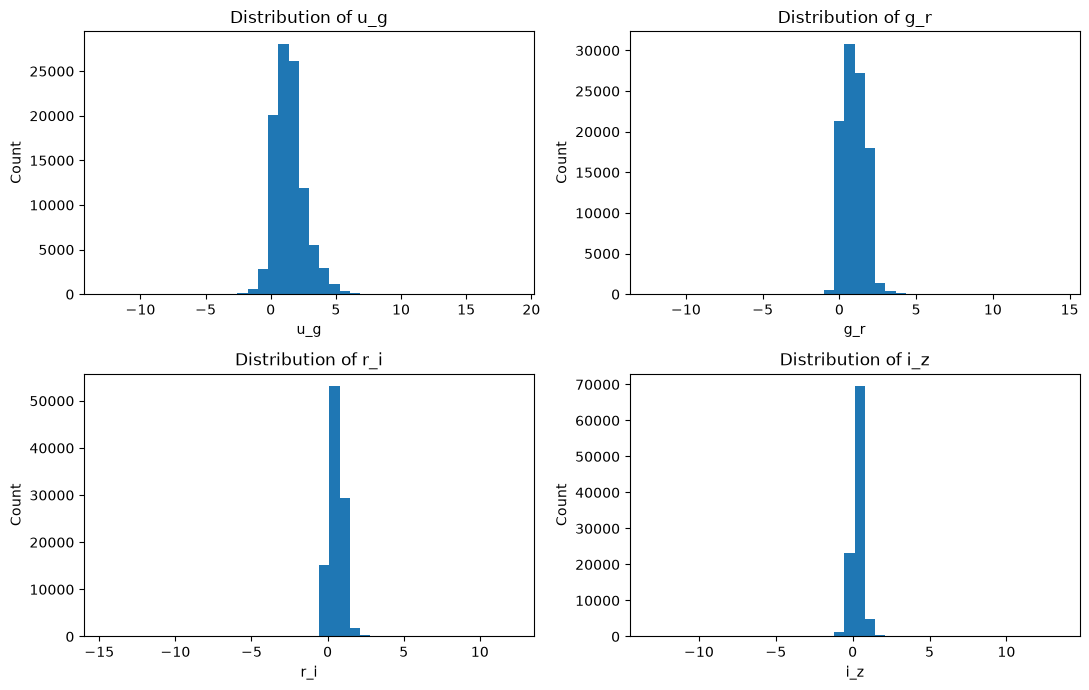

In [17]:
df_model = df_cleaned.copy()

# Create colour indices from the original photometric magnitudes.
df_model["u_g"] = df_model["u"] - df_model["g"]
df_model["g_r"] = df_model["g"] - df_model["r"]
df_model["r_i"] = df_model["r"] - df_model["i"]
df_model["i_z"] = df_model["i"] - df_model["z"]

COLOUR_FEATURES = ["u_g", "g_r", "r_i", "i_z"]

print("Derived feature summary:")
display(df_model[COLOUR_FEATURES].describe().T.round(3))

print("Missing values in derived features:")
display(df_model[COLOUR_FEATURES].isna().sum().to_frame("Missing count"))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for feature, ax in zip(COLOUR_FEATURES, axes.flatten()):
    ax.hist(df_model[feature].dropna(), bins=40)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

## 6. Separate features (X) and target (y)

The model input includes the six original measurements (`u`, `g`, `r`, `i`, `z`, and `redshift`) plus four derived colour indices. Coordinates remain available in the cleaned dataset for inspection but are not included in the primary experiment. The target is `class`.

In [18]:
TARGET = "class"

RAW_FEATURES = ["u", "g", "r", "i", "z", "redshift"]
COLOUR_FEATURES = ["u_g", "g_r", "r_i", "i_z"]
PRIMARY_FEATURES = RAW_FEATURES + COLOUR_FEATURES

X = df_model[PRIMARY_FEATURES].copy()
y = df_model[TARGET].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Original measurements:", RAW_FEATURES)
print("Derived colour features:", COLOUR_FEATURES)
print("Total model input columns:", len(PRIMARY_FEATURES))
print("Target classes:", sorted(y.unique()))

X shape: (100000, 10)
y shape: (100000,)
Original measurements: ['u', 'g', 'r', 'i', 'z', 'redshift']
Derived colour features: ['u_g', 'g_r', 'r_i', 'i_z']
Total model input columns: 10
Target classes: ['GALAXY', 'QSO', 'STAR']


## 7. Check class imbalance

Since the classes are not equally distributed and the GALAXY class is the largest class, while STAR and QSO are smaller. The class imbalance isn't very extreme but instead seemingly moderate still though **stratified** splitting is used.

,Count,Percentage
class,,
GALAXY,59445,59.44
STAR,21594,21.59
QSO,18961,18.96


Largest-to-smallest class count ratio: 3.14


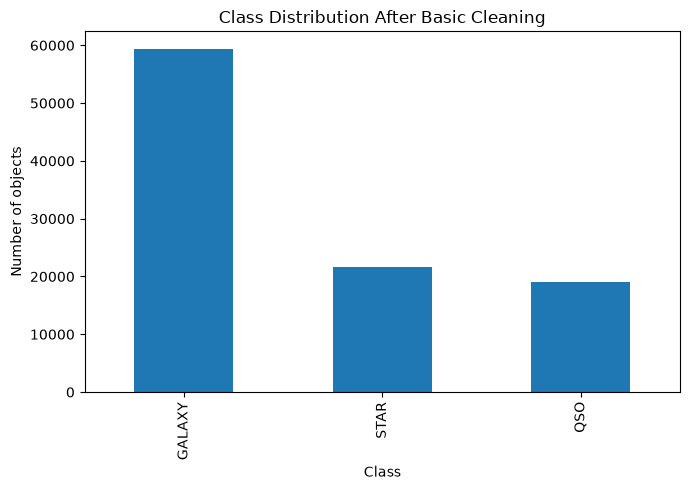

In [19]:
class_counts = y.value_counts()
class_percentages = (y.value_counts(normalize=True) * 100).round(2)
imbalance_table = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})
display(imbalance_table)
print("Largest-to-smallest class count ratio:", round(class_counts.max() / class_counts.min(), 2))

plt.figure(figsize=(7, 5))
class_counts.reindex(class_counts.index).plot(kind="bar")
plt.title("Class Distribution After Basic Cleaning")
plt.xlabel("Class")
plt.ylabel("Number of objects")
plt.tight_layout()
plt.show()

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

## 8. train_test_split
Since this is a classification problem and not a time-series prediction task, therefore a random stratified is appropriate. The test set is held out for final model evaluatio and `random_state=42` makes the split reproducible.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

split_distribution = pd.DataFrame({
    "Full dataset (%)": y.value_counts(normalize=True) * 100,
    "Training set (%)": y_train.value_counts(normalize=True) * 100,
    "Testing set (%)": y_test.value_counts(normalize=True) * 100
}).round(2)
display(split_distribution)



X_train: (80000, 10)
X_test: (20000, 10)
y_train: (80000,)
y_test: (20000,)


,Full dataset (%),Training set (%),Testing set (%)
class,,,
GALAXY,59.44,59.44,59.44
STAR,21.59,21.59,21.60
QSO,18.96,18.96,18.96


### Target Encoding

The Target contains GALAXY, STAR, QSO as strings which may be encoded using a `LabelEncoder`

> **Note to self:** Use this while decoding predicted_classes = label_encoder.inverse_transform(predictions)

In [22]:
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)

print("Class Mapping:")

for i, label in enumerate(label_encoder.classes_):
    print(label, ":", i)

print("\nEncoded Training Labels:")
print(y_train[:10])

Class Mapping:
GALAXY : 0
QSO : 1
STAR : 2

Encoded Training Labels:
[1 2 0 1 1 0 2 0 0 0]


## 9. Preprocessing
Since the main features are all numerical therefore no categorical encoding is required for `X` and the Target is encoded only using LabelEncoder.

> Median imputation is suitable as a simple baseline since it is less sensitive to extreme values.
>
> StandardScaler is also used for distance based and linear models such as KNN and LogisticRegression. 
>
> The imputer and scaler are fitted on `X_train` only. The same fitted transformations are then applied to `X_test`.


In [23]:
# preprocessor = Pipeline(steps=[
#     ("imputer", SimpleImputer(strategy="median")),
#     ("scaler", StandardScaler())
# ])

# X_train_processed = preprocessor.fit_transform(X_train)
# X_test_processed = preprocessor.transform(X_test)

# print("Processed training shape:", X_train_processed.shape)
# print("Processed testing shape:", X_test_processed.shape)
# print("Missing values remaining in processed training data:", np.isnan(X_train_processed).sum())
# print("Missing values remaining in processed testing data:", np.isnan(X_test_processed).sum())

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nMissing values in training data:")
display(X_train.isna().sum().to_frame("Missing count"))

print("\nMissing values in testing data:")
display(X_test.isna().sum().to_frame("Missing count"))

Training set shape: (80000, 10)
Testing set shape: (20000, 10)

Missing values in training data:


,Missing count
u,1
g,1
r,0
i,0
z,1
redshift,0
u_g,1
g_r,1
r_i,0
i_z,1



Missing values in testing data:


,Missing count
u,0
g,0
r,0
i,0
z,0
redshift,0
u_g,0
g_r,0
r_i,0
i_z,0


### Save the preprocessed training and testing data

Save the imputed and scaled train/test sets separately. The target is saved with its original class names so the CSV files remain understandable. The test data uses the imputer and scaler fitted on the training data; no test statistics are learned.

In [24]:
# Keep the original class names in the exported CSV files.
y_train_labels = label_encoder.inverse_transform(y_train)
y_test_labels = label_encoder.inverse_transform(y_test)

train_df = X_train.copy()
test_df = X_test.copy()

train_df[TARGET] = y_train_labels
test_df[TARGET] = y_test_labels

train_df.to_csv("Data/stellar_train_raw.csv", index=False)
test_df.to_csv("Data/stellar_test_raw.csv", index=False)

print("Training data saved:", train_df.shape)
print("Testing data saved:", test_df.shape)

Training data saved: (80000, 11)
Testing data saved: (20000, 11)


## 10. Initial feature selection (training data only)

Use `SelectKBest` with `f_classif` to select the four highest-scoring columns from the ten model inputs. `f_classif` calculates an ANOVA F-score for each feature separately, comparing variation between the target classes with variation within the classes.

The selector is fitted on the training data only. The selected subset is an initial experiment, not the final answer. In Phase 2, compare its performance with a model trained on all features and with an experiment using only the six original measurements.

**Important:** The four colour indices are calculated from the five original photometric bands. They add model columns, but they are not four additional independent telescope measurements. Record original measurements and derived model features separately when reporting reduction.

In [27]:
feature_selection_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("selector", SelectKBest(score_func=f_classif, k=4)),
    ("scaler", StandardScaler())
])

X_train_selected = feature_selection_pipeline.fit_transform(X_train, y_train)
X_test_selected = feature_selection_pipeline.transform(X_test)

selector = feature_selection_pipeline.named_steps["selector"]
selection_table = pd.DataFrame({
    "Feature": PRIMARY_FEATURES,
    "ANOVA F-score": selector.scores_,
    "Selected": selector.get_support()
}).sort_values("ANOVA F-score", ascending=False)

display(selection_table.round(3))
print("Selected features:", selection_table.loc[selection_table["Selected"], "Feature"].tolist())
print("Selected training shape:", X_train_selected.shape)
print("Selected testing shape:", X_test_selected.shape)

,Feature,ANOVA F-score,Selected
5,redshift,66422.725,True
7,g_r,19344.189,True
8,r_i,9690.164,True
4,z,8106.046,True
3,i,6652.801,False
6,u_g,5351.759,False
2,r,3700.980,False
0,u,3393.028,False
1,g,2989.421,False
9,i_z,2691.555,False


Selected features: ['redshift', 'g_r', 'r_i', 'z']
Selected training shape: (80000, 4)
Selected testing shape: (20000, 4)


## 11. Phase 1 Decision Table and Summary

| Requirement | Result / decision |
|---|---|
| Target | `class` (STAR, GALAXY, QSO) |
| Original model measurements | `u`, `g`, `r`, `i`, `z`, `redshift` |
| Derived colour features | `u_g`, `g_r`, `r_i`, `i_z` |
| Model input columns | 10 total: six original measurements and four derived features |
| Sentinel values | Replace `-9999` with `NaN` (one affected row; one missing value each in `u`, `g`, `z`) |
| Standard missing values in original file | None detected before sentinel conversion |
| Duplicate records | Checked and exact duplicates removed if present |
| IDs and survey metadata | Removed from cleaned modelling CSV with justification in the notebook |
| Outliers | Flagged with the IQR method; retained pending scientific/model-based investigation |
| Imputation | Median imputer, fitted on training data only |
| Scaling | StandardScaler for scale-sensitive models, fitted on training data only |
| Categorical encoding | Numerical inputs need no encoding; target labels encoded using `LabelEncoder` after the split |
| Split | 80% train / 20% test, `random_state=42`, `stratify=y` |
| Class imbalance | GALAXY is the majority class; use macro F1/per-class recall and consider class weights during modelling |
| Initial feature selection | SelectKBest (k=4 of 10 model columns) fitted on training data only; validate in Phase 2 |
| Resampling | Not applied in Phase 1; if needed later, apply only to training data |

**Feature-count note:** Colour indices are calculated from existing magnitudes. They increase the number of model input columns but do not increase the number of independent photometric measurements.

### Files produced

1. `star_classification.csv` — supplied original dataset, unchanged.
2. `star_classification_cleaned.csv` — basic-cleaned dataset with sentinel values represented as missing values and ID/metadata columns removed.
3. `stellar_train_preprocessed.csv` — imputed and scaled training inputs with the original target labels.
4. `stellar_test_preprocessed.csv` — imputed and scaled testing inputs with the original target labels.